![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 01 | Framing and Baseline

*Project 3 — AI Product: From Model to Product*

**Team:** Nacho Carbó Valle
**Track:** LLM (RAG assistant)
**Data:** 23,000 English Steam user reviews of 23 games, collected through Valve's `IUserReviewsService/GetAppReviews` API on 2026-11-10 (see section 2)

---

Frame the product, look at the data, fix your evaluation before you build anything, and score the baseline your solution will have to beat.

> **Done when:** your framing is written down, you know what one row or one document is and what is wrong with the data, your test set or evaluation set is fixed, and you can say your metric and your baseline score out loud.

**The user.** A PC player deciding whether to buy a game, or wondering how it runs and plays today. Steam shows a single score and thousands of unsorted reviews; reading enough of them to answer a specific question takes far too long.

**The input and the output.** The player asks a question in plain language ("How does Crimson Desert run on AMD cards?", "What do players with 100+ hours think of the late game in Elden Ring?"), optionally with filters: the game, a minimum playtime, a time period. The assistant answers from the reviews only, cites the ids of the reviews it used, and says "I don't know" when the reviews do not cover the question.

**The decision.** Buy now, wait for a patch or a sale, or skip the game.

**The metric, and which mistake costs more.**
1. **A confident wrong answer is the worst mistake.** The player spends money on something the assistant invented.
2. **A correct answer without a source** is next: the player cannot check it.
3. **A refusal is the cheapest mistake.** It is frustrating, but honest.

So I measure four things separately on the evaluation set: the **retrieval hit rate** (does the retriever find the right reviews?), **answer correctness**, **citation accuracy** (do the cited ids support the answer?), and whether the **out-of-scope questions are refused**. An assistant that refuses a little too often is better than one that invents.

**Why RAG and not the LLM alone.** These games are famous, so an LLM already knows a lot about them. Retrieval should add value where the LLM alone cannot help: games and patches released after its training cutoff, answers with checkable evidence, and filtered views (only long-time players, only one period). The baseline in section 8 tests exactly this.

---
## 0. Setup

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *
from sklearn.feature_extraction.text import CountVectorizer
from sentence_transformers import SentenceTransformer

pd.set_option("display.max_colwidth", 200)
sns.set_theme(style="whitegrid")

W1110 20:33:29.700000 54921 site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
sample = 'It’s “great”.....\n\n\n\n[b]ok[/b] see https://example.com'
expected = 'It\'s "great"...\n\nok see'
assert clean_text(sample) == expected, repr(clean_text(sample))
print("clean_text works as expected")

clean_text works as expected


---
## 1. Frame the product

Before any code. In a few sentences:

- **The user:** who uses your product, and in what situation?
- **The input and the output:** what do they give it, and what do they get back?
- **The decision:** what do they do with the output?
- **The metric:** how will you know it works, and which mistake costs more? (*Model track:* a missed complaint or a false alarm? *LLM track:* a wrong answer, an answer with no source, or a refusal?)

You wrote a first version on launch day. Refine it here.

---
## 2. Load the data



The reviews were collected once through Steam's official review API (`IUserReviewsService/GetAppReviews`, no key needed) and saved as a snapshot in `data/raw/steam_reviews/`, one parquet file per game. The list of games, their app ids and their Steam release dates is in `data/games.csv`. The collection code is in `src/functions.py` (`collect_all`).

**How the sample was drawn.** For each game, its life on Steam (release date → 2026-11-10) is split into **5 equal time windows**, and **200 reviews** are taken from each, so every period is covered, not just launch week. Within a window, I take the most *helpful* reviews (more informative texts), but **in the window's real share of positive and negative reviews**: sorting by helpfulness alone made the sample 20–30 points more negative than reality, because detailed complaints collect more helpful votes. This is stratified sampling, by time window × sentiment.

**Privacy.** The reviewer's SteamID is never stored; only aggregate author fields (playtime) are kept.

In [3]:
reviews = load_reviews()
games = pd.read_csv(ROOT / "data" / "games.csv")

print(reviews.shape)
print("Games:", reviews["game"].nunique())
print("Collected on:", reviews["collected_on"].unique())

(23000, 20)
Games: 23
Collected on: <ArrowStringArray>
['2026-11-10']
Length: 1, dtype: str


---
## 3. First look

Shape, columns, a handful of rows **read in full**. What is one row? For the Amazon data, join a few reviews to their product in the metadata file on `parent_asin`.

In [4]:
reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 23000 entries, 0 to 22999
Data columns (total 20 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   review_id             23000 non-null  str           
 1   app_id                23000 non-null  int64         
 2   game                  23000 non-null  str           
 3   text                  23000 non-null  str           
 4   voted_up              23000 non-null  bool          
 5   created               23000 non-null  datetime64[us]
 6   updated               23000 non-null  datetime64[us]
 7   playtime_at_review_h  23000 non-null  float64       
 8   playtime_forever_h    23000 non-null  float64       
 9   votes_up              23000 non-null  int64         
 10  votes_funny           23000 non-null  int64         
 11  steam_deck            23000 non-null  bool          
 12  received_for_free     23000 non-null  bool          
 13  refunded              23000

In [5]:
sample = reviews.sample(5, random_state=RANDOM_STATE)

for r in sample.itertuples():
    verdict = "👍" if r.voted_up else "👎"
    print(f"[{r.game}] {verdict} | {r.playtime_at_review_h:.0f} h | created {r.created:%Y-%m-%d} | window {r.window}")
    print(r.text)
    print("-" * 80)

[Dying Light] 👍 | 139 h | created 2022-12-10 | window 4
After all my years of gaming and as of this moment writing this review (12/2022). I sincerely believe this specific game (regardless of sequels) is my best zombie game experience by far. The DLCs the ongoing effort of events are totally optional but won't disappoint if you buy the bundle. Simply outstanding!
--------------------------------------------------------------------------------
[Hades] 👍 | 189 h | created 2021-05-17 | window 1
Supergiant is a probably the worst company in all of gaming, they make amazing games with no strings attached. What I hate is that there isn't more game to play after you experience everything, no horrendously  overpriced extra content to enjoy. Hades is their finest work with an amazing cast of characters, voice acting that is top tier, an extremely focused artstyle, music is fire, and combat is intuative and rewarding. Deadass is a masterpiece and one of the best games I've ever played.
---------

**What is one row?** One row is **one English review of one game, written by one Steam player**: 23 games × 5 time windows × 200 reviews = 23,000 rows. Its columns fall into five groups:

- **Identity:** `review_id` (what the assistant will cite), `app_id`, `game`.
- **Content:** `text`, and `voted_up`, the player's verdict (recommended or not).
- **Time:** `created` and `updated` (a review can be edited after it is posted, and Steam keeps only the latest version), and `window`, the time window it was sampled from.
- **Author context:** playtime when writing the review and in total, Steam Deck, received for free, refunded, and, for some reviews only, the `gpu`.
- **Sampling and community signals:** `votes_up` and `votes_funny`, plus `window_reviews_total` and `window_real_share`, which record how the sample relates to all the game's reviews in that window.

For the RAG system, `text` is what gets embedded and searched; the other columns become **metadata**, used to filter (game, playtime, period) and to cite. `developer_response` (3.5% of rows) is written by the studio, not the player, so it is not player evidence: I decide in section 7 whether the assistant searches it.

**What the five reviews already show:**
- **Irony.** A positive Hades review opens with "Supergiant is probably the worst company in all of gaming" before praising it. A search on words alone could retrieve it for a question about the game's flaws.
- **Other games are mentioned.** A Crimson Desert review compares it to Red Dead Redemption 2 and Skyrim, both in the corpus, so a question about one game can retrieve another game's review. This is an argument for filtering by game.
- **Long reviews mix topics.** One Baldur's Gate 3 review has separate sections (first minutes, gameplay loop, combat, romance). As a single chunk, its embedding mixes all of them, which raises the chunking question in section 7.
- **Typography varies:** curly quotes and apostrophes (“ ” ’) appear alongside straight ones, something to normalize when cleaning.

---
## 4. Data quality

Empty and very short texts, HTML (`<br />`, `&#34;`), duplicates, texts in other languages, missing titles or metadata. Write down what you find and what you will do about it. Put the cleaning in a function in `src/functions.py`: the app will need it too.

In [6]:
reviews["n_words"] = reviews["text"].str.split().str.len()

print(reviews["n_words"].describe(percentiles=[.1, .25, .5, .75, .9, .99]).round(1))
print("Empty texts:", (reviews["n_words"] == 0).sum())
print("3 words or fewer:", (reviews["n_words"] <= 3).sum())

count    23000.0
mean       188.1
std        254.6
min          1.0
10%         22.0
25%         39.0
50%         89.0
75%        224.0
90%        476.0
99%       1324.0
max       1735.0
Name: n_words, dtype: float64
Empty texts: 0
3 words or fewer: 21


In [7]:
patterns = {
    "BBCode tag": r"\[/?(?:h[1-3]|b|i|u|s|strike|spoiler|noparse|hr|list|olist|\*|url|quote|code|table|tr|th|td)(?:=[^\]]*)?\]",
    "URL": r"https?://\S+",
    "HTML entity": r"&[a-z]+;|&#\d+;",
    "Line break": r"\n",
}
for name, pattern in patterns.items():
    share = reviews["text"].str.contains(pattern, regex=True, case=False).mean()
    print(f"{name:12s} {share:6.1%}")

BBCode tag     9.8%
URL            3.2%
HTML entity    0.0%
Line break    62.1%


In [8]:
letters = reviews["text"].str.count(r"[A-Za-z]")
chars = reviews["text"].str.len().replace(0, 1)
reviews["letter_share"] = letters / chars

low = reviews[(reviews["letter_share"] < 0.5) & (reviews["n_words"] > 0)]
print("Reviews where less than half the characters are Latin letters:", len(low))
for t in low["text"].head(6):
    print(repr(t[:200]), "\n")

Reviews where less than half the characters are Latin letters: 117
'[h1] Всё, с меня хватит! [/h1]\nВпервые играю в игру подобного жанра, но кажется теперь буду больше. Наверное, я просто теперь буду жить в BG3! \n[hr][/hr]\n+ Наличие достаточного количества выбора, как ' 

'Захватывающее приключение с огромной вариативностью и порой не очевидными, удивляющими тебя механиками. Редко какую игру хочется пройти несколько раз, чтобы изучить всё что пропустил в первом прохожде' 

'🥶' 

'世一游 每一天都在期待更新 现在回想起沉迷博得之门的时光还是觉得很幸福。。全成就那天特别难受 不舍得拿最后一个成就 感觉拿到了就再也回不到这个快乐的时光qaq' 

'Baldur’s Gate 3 — одна из лучших игр, которые я проходил с искренним удовольствием от начала и до конца. Сразу отмечу: я не являюсь поклонником данного жанра. Divinity: Original Sin мне не зашла, а в ' 

'Балдура, что тут ещё сказать. Одна из лучших РПГ когда либо созданных. Интересна как соло так и в кооперативной пачке. Куча модов, дающих возможность играть как ты хочешь. До сих пор получает кучу обн' 



In [9]:
print("Duplicate review ids:", reviews["review_id"].duplicated().sum())

normalized = reviews["text"].str.strip().str.lower()
dups = reviews[normalized.duplicated(keep=False) & (reviews["n_words"] >= 5)]
print("Reviews sharing their exact text with another (5+ words):", len(dups))

(dups.assign(normalized=normalized)
     .groupby("normalized")["game"]
     .agg(["count", "nunique"])
     .sort_values("count", ascending=False)
     .head(10))

Duplicate review ids: 0
Reviews sharing their exact text with another (5+ words): 63


count  \
normalized                                                                                                                                                                                                        
you can do everything you can't do in real life, like casting magic and talking to girls                                                                                                                      6   
🟢[b] plug and play [/b]\n\ntested on: onexplayer mini pro 6800u\n\n[url=https://store.steampowered.com/curator/42772030-handheld-friendly/] follow handheld friendly [/url]                                   4   
imagine you're working in a 9-5 corporate job, you're done with your work, you come back home, log onto steam, see your games list for 5 seconds, buy a game on sale that you're never going to play ...      4   
---{graphics}---\n☑ you forget what reality is\n☐ beautiful\n☐ good\n☐ decent\n☐ bad\n☐ don‘t look too long at it\n☐ ms-dos\n\n---{gameplay}---\n☑ very good\n☐ good\n☐ it‘s just gameplay\n☐ mehh\n☐...      3   
this is the game that made me realize i really don't like metroidvanias. retracing my steps over and over and over grows tiring. distances between checkpoints and fast travel points are also way to...      2   
this is probably the first review i've ever written but i'm doing so to express my frustration with people's opinions of this remastered version. i feel like in the 5 years that this game has been ...      2   
this is a work of art! story, graphics, combat... 10/10                                                                                                                                                       2   
this game is almost perfection everything from the ultra-realistic renderings of japan to the combat to the acting is incredible. i also love the story and jin's conflicted nature about the rogue e...      2   
the only game where you can get married, have kids, run a college, become part of the upper echelon of every city, end a war, save the world, suck out the souls of dragons, become one of the greate...      2   
the note said "chest ahead" at the edge of a cliff with nothing in sight...there were plenty of bloodstains but they must've missed the jump... i had to be sure                                              2   

                                                                                                                                                                                                          nunique  
normalized                                                                                                                                                                                                         
you can do everything you can't do in real life, like casting magic and talking to girls                                                                                                                        2  
🟢[b] plug and play [/b]\n\ntested on: onexplayer mini pro 6800u\n\n[url=https://store.steampowered.com/curator/42772030-handheld-friendly/] follow handheld friendly [/url]                                     4  
imagine you're working in a 9-5 corporate job, you're done with your work, you come back home, log onto steam, see your games list for 5 seconds, buy a game on sale that you're never going to play ...        1  
---{graphics}---\n☑ you forget what reality is\n☐ beautiful\n☐ good\n☐ decent\n☐ bad\n☐ don‘t look too long at it\n☐ ms-dos\n\n---{gameplay}---\n☑ very good\n☐ good\n☐ it‘s just gameplay\n☐ mehh\n☐...        1  
this is the game that made me realize i really don't like metroidvanias. retracing my steps over and over and over grows tiring. distances between checkpoints and fast travel points are also way to...        1  
this is probably the first review i've ever written but i'm doing so to express my frustration with people's opinions of this remastered version. i feel like in the 5 years that this ga

In [10]:
reviews.groupby(reviews["created"].dt.year)["gpu"].apply(lambda s: s.notna().mean()).round(3)

created
2015    0.000
2016    0.004
2017    0.002
2018    0.006
2019    0.006
2020    0.008
2021    0.011
2022    0.008
2023    0.012
2024    0.017
2025    0.027
2026    0.296
Name: gpu, dtype: float64

**What I found**

| Check | Result | What I do |
|---|---|---|
| Length | Median 89 words, mean 188; 25% above 224 words, the longest 1,735. No empty texts, 21 with 3 words or fewer. | Drop texts under 5 words: they carry a verdict ("Peak") but nothing to retrieve. Long reviews are kept and chunked in section 7: the embedding model reads only the first ~256 tokens (about 190 words). |
| Steam markup (BBCode) | In 9.8% of reviews (`[h1]`, `[b]`, `[list]`, `[url=…]`…) | Remove the tags, keep the text inside them. |
| Links | In 3.2% of reviews | Remove them: they add noise to the embeddings, not meaning. |
| HTML entities | None | Nothing to do. |
| Line breaks | In 62.1% of reviews | Keep them, tidied: they separate paragraphs, which is where long reviews can be split. |
| Other languages | 117 reviews are mostly non-Latin text (Russian, Chinese) or emoji only, despite asking Steam for English. Chunking later revealed reviews in Latin-script languages too (Portuguese, Spanish, French, Turkish, German…), which the letter check cannot catch. | Two rules: non-Latin texts are removed by their share of Latin letters; other languages by a two-stage rule (explained below). |
| Duplicates | No duplicate review ids, but 63 reviews share their exact text with another one: memes, a curator's promotional template posted under 4 games, and copied reviews within the same game | Keep the first copy only. Otherwise identical copies fill several retrieval slots and the assistant would report one opinion as several players'. |
| GPU field | 0–3% of reviews from 2015 to 2025, 29.6% in 2026 | Steam only recently attached hardware to reviews, so GPU filters only work for recent reviews. Older reviews can still mention hardware in the text. |
| Typography | Curly and straight quotes and apostrophes are mixed | Normalize to straight ones. |

**How the language rule was built, in two iterations.** In section 7, the chunk checks failed on reviews in Spanish and Hungarian, which the letter check cannot catch. A first rule removed reviews of 20+ words in which fewer than 20% of the words are English function words ("the", "and", "it"…). Checking both sides of that threshold showed it was wrong: terse English reviews, such as lists ("1. Dual Protagonists and Contrasting Playstyles…") or telegraphic verdicts ("Gameplay good, shoot web good…"), also contain almost no function words. A language detector (`langdetect`) found that **48 of the 151 reviews it removed were English**.

The final rule has two stages: the function-word share (below 0.3) only flags **suspects**, and `langdetect`, run on the suspects only, decides which are in another language. It removes 116 reviews, none of them detected as English.

**Remaining limitation:** bilingual reviews that include an English version ("ENG: Far Cry 6 is a true classic FPS…") are detected as their other language and removed. They are a small share of the corpus, and keeping them would also put their non-English half into the index.

In [11]:
clean, removal_log = prepare_reviews(reviews)

print(f"{len(reviews):,} reviews → {len(clean):,} after cleaning")
removal_log

23,000 reviews → 22,707 after cleaning


,reason,rows_removed
0,"Mostly non-Latin characters (other language, emoji, ASCII art)",105
1,Fewer than 5 words,20
2,Not English (language detected on suspects with few English function words),116
3,Exact duplicate text (first copy kept),52


In [12]:
borderline = clean[(clean["n_words"] >= 20) & (clean["english_share"] < 0.3)].sort_values("english_share")
print(f"Kept reviews with a low share of English function words: {len(borderline)}")
show_reviews(borderline, n=4, chars=300)

Kept reviews with a low share of English function words: 299
[God of War] 👍 | 30 h | 2024-07-14 | window 3 | id 169816019
Graphics: 8.5/10

Story: 8/10

Combat:8/10

Characters: 9/10

Soundtrack: 7.7/10

Ending: 9/10

Open World:9/10

Fights/Bosses: 9/10

Cinematic: 9/10

Character Development:7.2/10

Content: 9.4/10

Overall Rating: 8.7/10

Personal Rating: 9/10
--------------------------------------------------------------------------------
[The Last of Us Part I] 👍 | 15 h | 2024-07-20 | window 2 | id 170340458
Category
Score

🏆 Overall Rating
★★★

📖 Story
★★★

🎮 Gameplay
★★★

🎨 Graphics
★★★

🎵 Sound Design
★★★

↩ Replay Value
★★★

😧 Difficulty
★★★☆☆

🐛 Bug free?
★★★

🖥️ PC Requirements
★★★☆

📈 Game Length
▰▰▰▱▱▱
--------------------------------------------------------------------------------
[Sekiro: Shadows Die Twice] 👍 | 33 h | 2021-07-18 | window 2 | id 95981265
~ DIFFICULTY ~

🔲 Roblox obby
🔲 Easy
🔲 Normal
🔲 Hard
🔲 Dark Souls
✅ Sekiro: Shadows Die Twice
-------------------------

In [13]:
without_rule, _ = prepare_reviews(reviews, screen_english_share=0)     # language rule switched off

# What the first version of the rule (function-word share < 0.2) would remove, and what those reviews really are
old_rule = without_rule[(without_rule["n_words"] >= 20) & (without_rule["english_share"] < 0.2)].copy()
old_rule["language"] = old_rule["text"].map(detect_language)
print(f"The function-word rule alone would remove {len(old_rule)} reviews. Their detected languages:")
print(old_rule["language"].value_counts())

The function-word rule alone would remove 151 reviews. Their detected languages:
language
en    48
pt    31
es    23
fr    13
tr    10
de     7
hu     3
pl     3
no     3
it     2
sk     2
nl     2
cs     1
hr     1
vi     1
id     1
Name: count, dtype: int64


In [14]:
removed_by_rule = without_rule[~without_rule["review_id"].isin(clean["review_id"])].copy()
removed_by_rule["language"] = removed_by_rule["text"].map(detect_language)
print(f"Removed by the two-stage language rule: {len(removed_by_rule)}")
print(removed_by_rule["language"].value_counts(), "\n")

preview = removed_by_rule.sort_values("english_share", ascending=False).head(15)
preview.assign(start=preview["text"].str[:90].str.replace("\n", " "))[["game", "language", "english_share", "start"]].round(3)

Removed by the two-stage language rule: 116
language
pt    34
es    26
fr    16
tr    10
de     8
pl     4
hu     4
it     3
no     3
sk     2
nl     2
cs     1
hr     1
vi     1
id     1
Name: count, dtype: int64 



,game,language,english_share,start
3683,Red Dead Redemption 2,fr,0.291,"[ENGLISH] ""With the depth of gameplay and storyline as well as the overwhelming open world"
85,Baldur's Gate 3,pl,0.289,"EN The best game I've played in years, not counting Disco Elysium. Update: I wrote this"
14958,Crimson Desert,de,0.287,"Eine klare Kaufempfehlung ! ( English Version Below ) Wieder einmal zeigt sich, je schlec"
22699,Hogwarts Legacy,pt,0.277,Nota Geral | Overall Rating ⭐⭐⭐ Hogwarts Legacy é a prova de que dava para fazer um jogo
16964,007 First Light,fr,0.271,"I should start by saying that I'm not a fan of James Bond movies, nor the Hitman games. I"
730,Baldur's Gate 3,fr,0.262,"English version : Everything about this game is great : the story, the gameplay, the vari"
11212,Far Cry 6,hu,0.261,ENG: Far Cry 6 is a true classic FPS that is a must-have for every fan. The enormous open
4735,Elden Ring,it,0.259,"Very repetitive, punishing and redundant gameplay. The lore, despite being very exciting t"
8772,Marvel's Spider-Man Remastered,es,0.256,Recommended – Recomendado (ENG / ES) Game: Marvel's Spider-Man Remastered is an open-wor
1669,Cyberpunk 2077,es,0.233,"ni cuenta me di de las horas que le tengo a este maldito juego, juego de porqueria es buen"


In [15]:
has_markup = reviews["text"].str.contains(r"^\s*\[(?:h1|b|list)\]", regex=True)
example_id = reviews.loc[has_markup & reviews["review_id"].isin(clean["review_id"]), "review_id"].iloc[0]

print("BEFORE:", repr(reviews.loc[reviews["review_id"] == example_id, "text"].iloc[0][:400]))
print()
print("AFTER: ", repr(clean.loc[clean["review_id"] == example_id, "text"].iloc[0][:400]))

BEFORE: "[h1] This game is so utterly magnificent that it made me write a poem about itself [/h1]\n\n[b] In the poor sea of releases, a jewel divine, \nBaldur's Gate 3’s where splendor refines.\nA brilliant adventure, where memories made,\nIn every your choice a legacy laid.\n\nFrom Astarion's secrets to Shadowheart's grace,\nEach personality finds its space. \nAesthetics are gorgeous, a visual dance,\nFrom dawn's f"

AFTER:  "This game is so utterly magnificent that it made me write a poem about itself\n\nIn the poor sea of releases, a jewel divine,\nBaldur's Gate 3's where splendor refines.\nA brilliant adventure, where memories made,\nIn every your choice a legacy laid.\n\nFrom Astarion's secrets to Shadowheart's grace,\nEach personality finds its space.\nAesthetics are gorgeous, a visual dance,\nFrom dawn's first light to twi"


In [16]:
print("BBCode tags left:", clean["text"].str.contains(BBCODE_TAG).sum())
print("URLs left:", clean["text"].str.contains(URL).sum())
print("Edited more than a day after posting:", f"{clean['edited'].mean():.1%}")
clean.groupby("game").size().sort_values().head()

BBCode tags left: 0
URLs left: 0
Edited more than a day after posting: 18.5%


game
Marvel's Spider-Man Remastered    979
007 First Light                   980
The Witcher 3: Wild Hunt          981
Baldur's Gate 3                   981
God of War                        983
dtype: int64

**After cleaning: 23,000 → [X] reviews** ([X] removed, [X]% of the corpus).

| Rule (applied in this order) | Rows removed |
|---|---|
| Mostly non-Latin characters (other languages, emoji only, ASCII art) | 105 |
| Fewer than 5 words | 20 |
| Another language, detected by `langdetect` among suspects with few English function words (20+ words) | 116 |
| Exact duplicate text (first copy kept) | [X] |

- **The rules run on the cleaned text**, so the counts differ slightly from the raw measurements above. The 63 duplicated reviews form groups of copies, and only the extra copies are removed.
- **No BBCode tags or links remain.**
- **The sample stays balanced across games:** every game keeps at least [X] of its 1,000 reviews. [Game] ([X] removed) and [game] ([X]) lose the most.
- **The language rule was checked from both sides.** Among the kept suspects, those with the fewest function words are terse but English, and `langdetect` confirms it. Among the removed reviews, none is detected as English; those closest to English are the bilingual reviews described above.
- **[X]% of the reviews were edited more than a day after posting.** Steam keeps only the latest version, so for these reviews the text and the verdict reflect what the player thinks *now*, not what they wrote at the time. This matters for questions about how a game was received at launch, so the `edited` flag is kept as metadata.

---
## 5. Look at the texts

Lengths, the most frequent words, how the texts differ between ratings, products or periods. Read some hard cases: the 3-star reviews, the sarcastic ones, the ones whose rating and text disagree.

### 5.1 Length by verdict and game

            count   25%    50%    75%
verdict                              
negative   2710.0  48.0  104.0  258.0
positive  19997.0  39.0   87.0  219.0


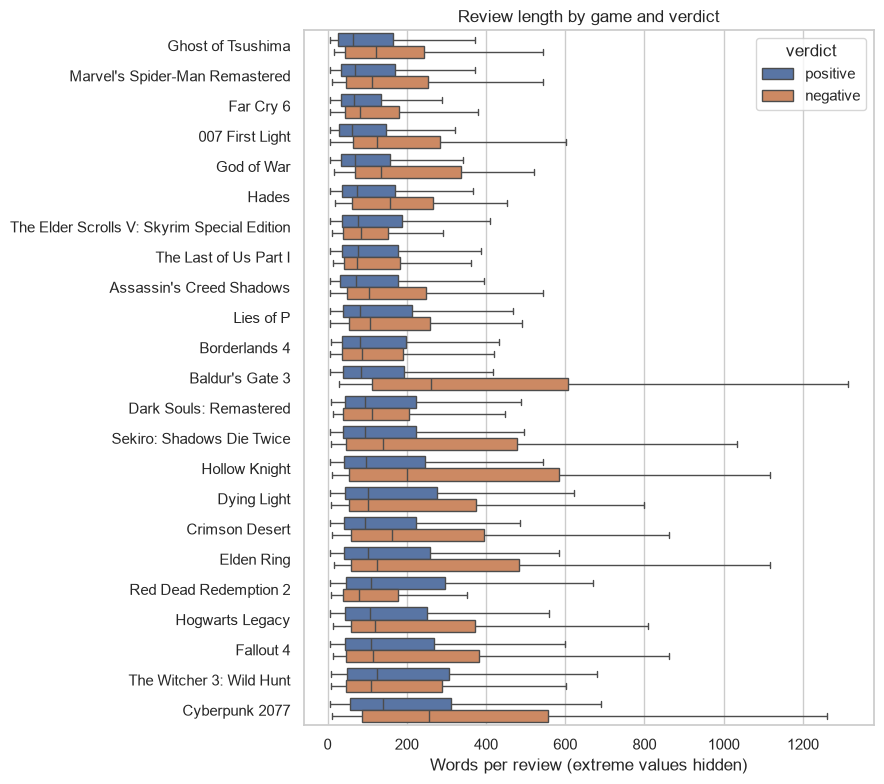

In [17]:
clean["verdict"] = clean["voted_up"].map({True: "positive", False: "negative"})
print(clean.groupby("verdict")["n_words"].describe()[["count", "25%", "50%", "75%"]])

order = clean.groupby("game")["n_words"].median().sort_values().index
plt.figure(figsize=(9, 8))
sns.boxplot(data=clean, y="game", x="n_words", hue="verdict", order=order, showfliers=False)
plt.title("Review length by game and verdict")
plt.xlabel("Words per review (extreme values hidden)")
plt.ylabel("")
plt.tight_layout()
plt.show()

**Negative reviews are somewhat longer.** The median negative review has 104 words (75th percentile: 258), the median positive one 87 (75th percentile: 219). This is consistent with what I found when collecting the data: complaints tend to be explained in detail, which is why sorting by helpfulness alone over-selected negative reviews. The gap is largest in the best-rated games: in Baldur's Gate 3, Hollow Knight and Sekiro, the few negative reviews are often essays. Those boxes rest on few reviews (Hollow Knight has about 30 negative ones), so they are noisy.

The longest positive reviews belong to big open-world RPGs (Cyberpunk 2077, The Witcher 3, Fallout 4), the shortest to Ghost of Tsushima, Spider-Man and Far Cry 6. **Consequence for section 7:** long reviews, and especially long negative ones, need to be chunked, or the embedding model will ignore everything after its first ~256 tokens.

### 5.2 Words typical of negative and positive reviews

In [18]:
vectorizer = CountVectorizer(stop_words="english", binary=True, min_df=30)
X = vectorizer.fit_transform(clean["text"])
words = vectorizer.get_feature_names_out()

is_pos = clean["voted_up"].to_numpy()
terms = pd.DataFrame({
    "word": words,
    "share_neg": np.asarray(X[~is_pos].mean(axis=0)).ravel(),
    "share_pos": np.asarray(X[is_pos].mean(axis=0)).ravel(),
})
terms["ratio"] = (terms["share_neg"] + 0.001) / (terms["share_pos"] + 0.001)

cols = ["word", "share_neg", "share_pos"]
top_negative = terms.sort_values("ratio", ascending=False).head(20)[cols].round(3).reset_index(drop=True)
top_positive = terms.sort_values("ratio").head(20)[cols].round(3).reset_index(drop=True)
pd.concat({"Typical of NEGATIVE reviews": top_negative, "Typical of POSITIVE reviews": top_positive}, axis=1)

Typical of NEGATIVE reviews                      \
                          word share_neg share_pos   
0                      gearbox     0.030     0.002   
1                        email     0.012     0.000   
2                    customers     0.014     0.001   
3                 unacceptable     0.013     0.001   
4                       refund     0.040     0.004   
5                     soulless     0.014     0.001   
6                    compiling     0.011     0.001   
7                        randy     0.021     0.002   
8                   unplayable     0.031     0.004   
9                      garbage     0.042     0.005   
10                 unoptimized     0.010     0.001   
11                    consumer     0.011     0.001   
12                    existent     0.012     0.001   
13                     abysmal     0.014     0.001   
14                   painfully     0.016     0.002   
15                     shaders     0.032     0.004   
16                       bland     0.044     0.006   
17                    launcher     0.033     0.005   
18                         bl4     0.017     0.002   
19                    customer     0.008     0.001   

   Typical of POSITIVE reviews                      
                          word share_neg share_pos  
0                      eargasm     0.001     0.024  
1                    terrarium     0.001     0.024  
2                         mehh     0.001     0.023  
3                          boi     0.001     0.022  
4                          dos     0.001     0.021  
5                        teens     0.001     0.024  
6                          ark     0.001     0.023  
7                       arthur     0.000     0.014  
8                       coffee     0.001     0.024  
9                 leaderboards     0.001     0.023  
10                          ms     0.001     0.023  
11               unforgettable     0.001     0.019  
12                    infinity     0.002     0.025  
13                      adults     0.002     0.025  
14                     grandma     0.001     0.021  
15                        rich     0.006     0.056  
16                      morgan     0.000     0.010  
17                       ranks     0.002     0.024  
18                     journey     0.006     0.050  
19                  perfection     0.000     0.009

**What players complain about.** The words most typical of negative reviews fall into three themes:
- **Technical problems:** *unplayable* (in 3.1% of negative reviews vs. 0.4% of positive ones), *shaders* and *compiling* (long shader compilation), *launcher*, *unoptimized*.
- **The developer or publisher, and the buyer's rights:** *refund* (4.0% vs. 0.4%), *customers*, *consumer*, *gearbox* and *randy* (Borderlands 4's studio and its CEO, Randy Pitchford).
- **Quality judgments:** *garbage*, *bland*, *soulless*, *abysmal*.

**One game dominates this list.** *gearbox*, *randy* and *bl4* all point to Borderlands 4, which, at about 49% positive, supplies nearly one in five of the corpus's negative reviews. So complaint vocabulary is not evenly spread: for most games, negative evidence is scarce.

**What players praise:** [fill in from the positive list, e.g. *journey* (4.9% of positive reviews vs. 0.6% of negative ones), *perfection*, *morgan* (Arthur Morgan, RDR2's protagonist)].

**Consequence for the evaluation set:** complaint questions are well supported for Borderlands 4, Far Cry 6 or Assassin's Creed Shadows, but for games like Hollow Knight or Hades the assistant will have little negative evidence. A good test is whether it says so rather than inventing complaints.

### 5.3 Mentions of other games in the corpus

In [19]:
aliases = {
    "Baldur's Gate 3": r"baldur|\bbg3\b",
    "Elden Ring": r"elden ring",
    "Cyberpunk 2077": r"cyberpunk",
    "Red Dead Redemption 2": r"red dead|\brdr ?2\b",
    "Hollow Knight": r"hollow knight",
    "The Witcher 3: Wild Hunt": r"witcher",
    "Hades": r"\bhades\b",
    "The Elder Scrolls V: Skyrim Special Edition": r"skyrim",
    "Sekiro: Shadows Die Twice": r"sekiro",
    "Dark Souls: Remastered": r"dark souls",
    "Borderlands 4": r"borderlands",
    "Dying Light": r"dying light",
    "Hogwarts Legacy": r"hogwarts",
    "God of War": r"god of war",
    "Marvel's Spider-Man Remastered": r"spider-?man",
    "Far Cry 6": r"far cry",
    "007 First Light": r"\b007\b|james bond",
    "Crimson Desert": r"crimson desert",
    "Assassin's Creed Shadows": r"assassin'?s creed",
    "Lies of P": r"lies of p\b",
    "Fallout 4": r"fallout",
    "The Last of Us Part I": r"last of us|\btlou\b",
    "Ghost of Tsushima": r"tsushima",
}
assert set(aliases) == set(clean["game"]), "Alias names must match the game names in the data"

mentions = pd.DataFrame({g: clean["text"].str.contains(p, case=False, regex=True) for g, p in aliases.items()})

# Mentions of a game *other* than the one being reviewed
own = clean["game"].map({g: i for i, g in enumerate(aliases)}).to_numpy()
other = mentions.to_numpy().copy()
other[np.arange(len(other)), own] = False
clean["mentions_other_game"] = other.any(axis=1)

print(f"Reviews mentioning another game in the corpus: {clean['mentions_other_game'].mean():.1%}")
clean.groupby("game")["mentions_other_game"].mean().sort_values(ascending=False).round(3).head(8)

Reviews mentioning another game in the corpus: 13.2%


game
Sekiro: Shadows Die Twice    0.322
Lies of P                    0.315
Crimson Desert               0.241
Elden Ring                   0.238
Cyberpunk 2077               0.217
Ghost of Tsushima            0.173
The Witcher 3: Wild Hunt     0.170
Fallout 4                    0.146
Name: mentions_other_game, dtype: float64

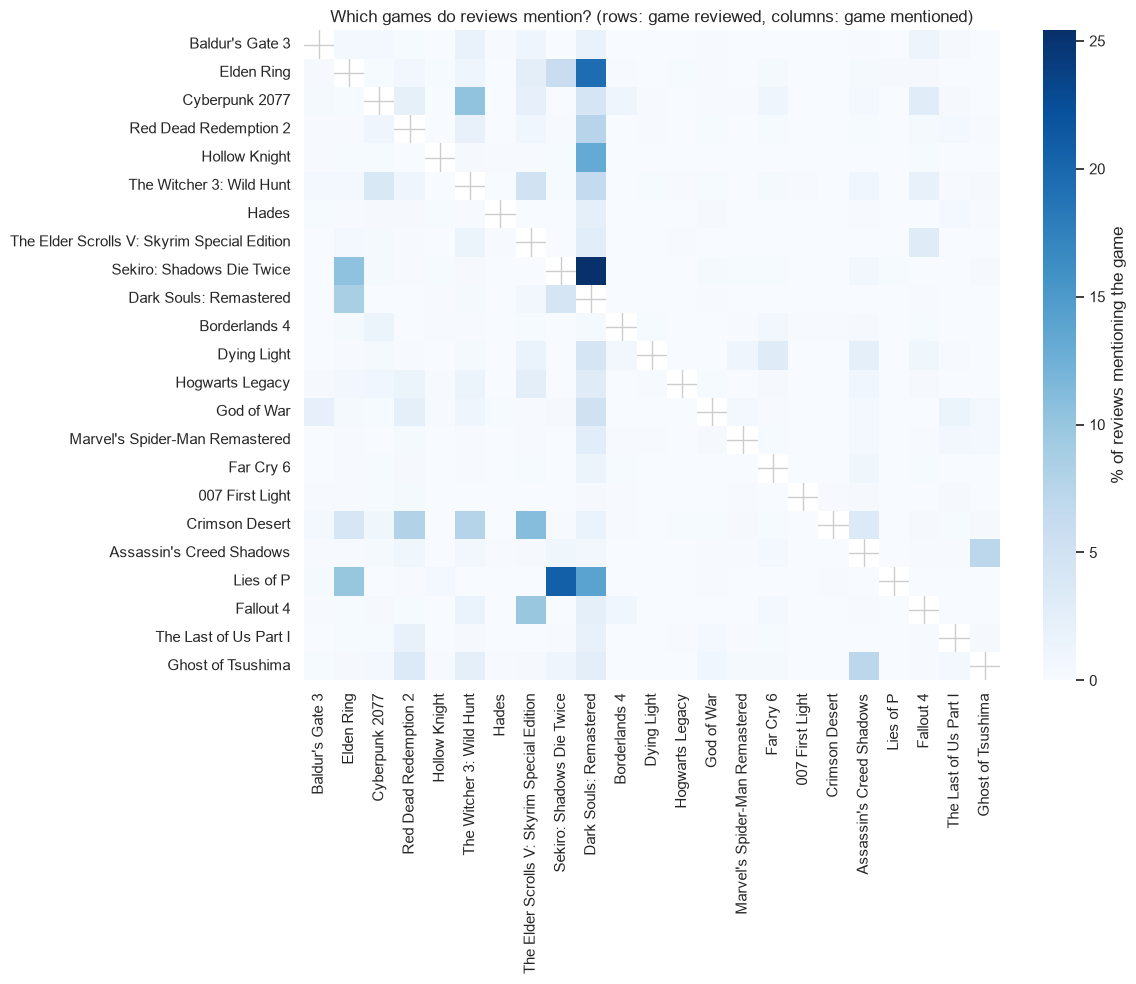

In [20]:
cross = mentions.groupby(clean["game"]).mean().loc[list(aliases), list(aliases)] * 100

plt.figure(figsize=(12, 10))
sns.heatmap(cross, mask=np.eye(len(aliases), dtype=bool), cmap="Blues",
            cbar_kws={"label": "% of reviews mentioning the game"})
plt.title("Which games do reviews mention? (rows: game reviewed, columns: game mentioned)")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

**13.2% of reviews mention another game in the corpus**, and some games far more: Sekiro (32%), Lies of P (31%), Crimson Desert (24%), Elden Ring (24%), Cyberpunk 2077 (22%). The heatmap shows clear clusters:
- **"Dark Souls" is used as a genre word.** Its column is the darkest by far: reviews of Sekiro (about 25%), Elden Ring, Lies of P and even Hollow Knight compare them to Dark Souls. A question about Dark Souls would therefore retrieve many reviews of other games.
- **The same studio:** The Witcher 3 ↔ Cyberpunk 2077 (CD Projekt Red), Skyrim ↔ Fallout 4 (Bethesda).
- **The same theme:** Assassin's Creed Shadows ↔ Ghost of Tsushima (feudal Japan).
- **A newcomer compared with the classics:** Crimson Desert reviews mention Skyrim, The Witcher 3 and Red Dead Redemption 2.

The aliases also catch series names (*witcher* matches The Witcher 2), which is acceptable here: those mentions confuse the retriever in the same way.

**Consequences:** (1) without a **game filter**, retrieval will mix games, which I will measure as a design choice in notebook 02. (2) These comparisons are also useful evidence: "How does Lies of P compare to Sekiro?" can be answered from Lies of P reviews, a good question for the evaluation set.

### 5.4 Performance complaints across time windows

In [21]:
performance = r"\b(?:stutter\w*|crash\w*|fps|frame ?rate|performance|optimi[sz]\w*|lag\w*)\b"
clean["mentions_performance"] = clean["text"].str.contains(performance, case=False, regex=True)

perf_by_window = clean.pivot_table(index="game", columns="window",
                                   values="mentions_performance", aggfunc="mean")
(perf_by_window * 100).round(1).sort_values(1, ascending=False).head(10)

window,1,2,3,4,5
game,,,,,
Borderlands 4,73.4,41.5,44.0,51.5,50.5
The Last of Us Part I,61.6,47.2,25.1,24.2,16.8
Dark Souls: Remastered,34.5,13.1,4.1,6.7,4.5
Cyberpunk 2077,32.2,29.6,23.6,12.2,13.9
Elden Ring,31.5,8.7,4.6,7.5,7.5
Red Dead Redemption 2,29.6,10.1,6.6,6.2,6.6
007 First Light,28.0,9.8,7.6,11.7,13.5
Fallout 4,27.9,14.2,14.8,15.6,11.6
Ghost of Tsushima,27.4,10.2,8.1,10.7,7.6


**Performance complaints usually fade after launch, but not always.** Share of each game's reviews mentioning performance, by time window (1 = launch):

- **Fixed:** The Last of Us Part I falls steadily from 61.6% to 16.5%; Dark Souls: Remastered from 34.5% to 4.5%; Elden Ring from 31.2% to 8.6% already in window 2.
- **Slow improvement:** Cyberpunk 2077 stays near 30% for two windows before falling to 12–14%.
- **Never fixed:** Borderlands 4 starts at 73.4% and still sits at about 50% in the last two windows.
- **A late bump:** Fallout 4 rises again in window 4 (16.0%), possibly linked to a later update; a hypothesis to check in the texts.

**Limitation:** the pattern counts *mentions*, so "runs at a stable 60 fps" counts too; these percentages measure how much players talk about performance, not only how much they complain.

**Consequence for the evaluation set:** these trajectories are ready-made "then vs. now" questions ("Has The Last of Us Part I's PC port improved since launch?", "Does Borderlands 4 still have performance problems?"), with a known expected answer.

### 5.5 Hard cases

In [22]:
says_dont_buy = r"\b(?:don't buy|do not buy|not recommend|refund(?:ed)?|waste of money)\b"
says_love_it = r"\b(?:masterpiece|10/10|love this game|best game)\b"

pos_but_negative = clean[clean["voted_up"] & clean["text"].str.contains(says_dont_buy, case=False, regex=True)]
neg_but_positive = clean[~clean["voted_up"] & clean["text"].str.contains(says_love_it, case=False, regex=True)]
print(f"Positive reviews with 'don't buy' language: {len(pos_but_negative)}")
print(f"Negative reviews with 'masterpiece' language: {len(neg_but_positive)}\n")

show_reviews(pos_but_negative.sample(3, random_state=RANDOM_STATE))
show_reviews(neg_but_positive.sample(3, random_state=RANDOM_STATE))

Positive reviews with 'don't buy' language: 287
Negative reviews with 'masterpiece' language: 131

[Baldur's Gate 3] 👍 | 11 h | 2025-10-12 | window 4 | id 206552485
Imagine you purchased an shitty unoptimized next gen game for 80$ and it made you so mad for what little you get these days with 80 or even 100 bucks.. you refund it and give Baldurs Gate 3 a try since everybody you know keeps glazing it, friends storming me on the toilet when im taking a shit just to tell me how good this game is preventing me from taking care of my private business.. coudlnt be me right?

The amount of freedom and content you get in a game that costs 60$, has Ultrawide support 32:9 and 21:9 ,is so well optimized that you can easily get 60 or 200fps without the todays standard DLSS..

you can play it in co op with your friends, even playing with console players is possible

Its like GTA 5 with a Fantasy setting, thats the shorttest description and the best example i can c
----------------------------------

In [23]:
show_reviews(clean.sort_values("votes_funny", ascending=False), n=4)

[The Witcher 3: Wild Hunt] 👍 | 130 h | 2016-05-10 | window 1 | id 22901619
You can do everything you can't do in real life, like casting magic and talking to girls
--------------------------------------------------------------------------------
[Fallout 4] 👍 | 74 h | 2015-11-14 | window 1 | id 19077603
I have lost 10lbs since starting Fallout 4 because I keep forgetting to eat. 10/10 - best fitness game on Steam.
--------------------------------------------------------------------------------
[Elden Ring] 👍 | 19 h | 2022-02-27 | window 1 | id 111180228
The note said "chest ahead" at the edge of a cliff with nothing in sight...there were plenty of bloodstains but they must've missed the jump... I had to be sure
--------------------------------------------------------------------------------
[Assassin's Creed Shadows] 👍 | 3 h | 2025-03-20 | window 1 | id 190688263
AC Shadows is a game that tells the story of Johnny Somali, who time travels to the feudal era of Japan.
--------------------

In [24]:
low_play = clean[clean["playtime_at_review_h"] < 1]
print(f"Reviews written with less than 1 hour played: {len(low_play)} "
      f"({low_play['voted_up'].mean():.0%} positive)")
show_reviews(low_play.sample(3, random_state=RANDOM_STATE))

Reviews written with less than 1 hour played: 375 (58% positive)
[Ghost of Tsushima] 👍 | 1 h | 2024-05-16 | window 1 | id 165473996
Ghost of Tsushima
The game seems to be the best in recent times. After Red Dead Redemption 2, it is now playing another game that has caught the same.
Gameplay/Graphics/Story/Audio/Visuals/Combats all better one by one. After starting the game, I didn't want to stop. The Game is Just Wow.
But having bugs is absolutely disgusting. Especially the Audio Bug that came after going to IKI Island 🤢 Similarly, Legend Mode is utterly buggy. Bugs aside, Game is 10/10 for me. Hope they will fix the bugs soon
---{ Graphics }---
☑ From Another Dimension
☐ Great
☐ Good
☐ Decent
☐ Bad

---{ Gameplay }---
☑ Very good
☐ Good
☐ It's just gameplay
☐ Worst
☐ Watch Cartoon Instead

---{ Optimization }---
☐ Sweet Potato
☐ Potato
☑ Decent
☐ Need Good RIg
☐ Only for Rich Bois

---{ Story }---
☐ No Story
☐ Average
-------------------------------------------------------------------

**Hard cases.**
- **The verdict is not a label for every aspect of the game.** 288 positive reviews use "don't buy" or "refund" language, and 131 negative ones use "masterpiece" language. Most are not contradictions but nuance: a negative The Last of Us Part I review (id 141067758) calls the game "AMAZING" and is negative only because of the PC port. One thumb summarizes several opinions, so the assistant must read the text, not just the verdict.
- **Jokes.** The reviews voted funniest are not opinions: "best fitness game on Steam" because the player forgot to eat (Fallout 4, id 19077603), a meme about "casting magic and talking to girls" (The Witcher 3, id 22901619), a joke about Elden Ring's player messages (id 111180228). Cited as evidence, they would produce absurd answers. `votes_funny` stays as metadata so they can be recognized.
- **Steam playtime misses console experience.** 375 reviews were written after less than an hour on Steam, and only 58% of them are positive (refunds and launch problems). But one Ghost of Tsushima review (id 165473996), written after about an hour on Steam, discusses late-game content: the player had played it on PlayStation before. A minimum-playtime filter would wrongly exclude such reviews, so its effect has to be measured, not assumed.
- **Templates.** Checklist reviews ("---{ Graphics }---" followed by ticked boxes) are common and carry little real information.

**What section 5 means for the system:**
1. **Chunk long reviews**, so each part can be retrieved on its own: one long review often holds several opinions.
2. **Filter by game**, because 13.2% of reviews mention another game, and "Dark Souls" is used as a genre word.
3. **Keep `created`, `window`, `edited`, `votes_funny` and playtime as metadata**, to filter by period and to recognize jokes and launch-week opinions.
4. **Write evaluation questions** that test what I found here: then vs. now (The Last of Us Part I, Borderlands 4), comparisons (Lies of P vs. Sekiro), complaints for games with little negative evidence (Hollow Knight), and hard cases (the mixed The Last of Us review, the jokes).

---
## 6. Model track — the target and the split

Skip this section on the LLM track.

- **Define the target** with a stated rule, for example stars to sentiment, and show the share of each class.
- **Split once**: a fixed `RANDOM_STATE`, stratified. Decide whether the split is random, by product (`parent_asin`) or by time, and say why. The test set is not touched again until notebook 03.

*Skipped: this project is on the LLM track.*

---
## 7. LLM track — the documents and the evaluation set

Skip this section on the model track.

### 7a. The documents

**What the system searches:** the cleaned player reviews. Developer responses (3.5% of reviews) are written by the studio, so they are not evidence of what players experienced; they stay out of the index.

**How reviews are chunked.** The embedding model (`all-MiniLM-L6-v2`) only reads a limited number of tokens and silently ignores the rest, so I first measure that limit and how many reviews exceed it. Then:
- a review that fits within **200 tokens** stays a single chunk;
- a longer review is split into paragraphs, and consecutive paragraphs are packed together up to 200 tokens;
- a single paragraph that is too long is split into sentences, and as a last resort into fixed groups of words.

Following the paragraphs matters because long reviews often hold several opinions (section 5: a review praising The Last of Us Part I's story but condemning its PC port). A chunk per part lets the retriever find the part that answers the question. 200 tokens, rather than the model's maximum, leaves headroom and keeps chunks focused; chunk size is a design choice I can compare in notebook 02.

**Metadata.** Every chunk keeps its review's metadata: game, verdict, creation date, time window, playtime at review, edited flag, funny votes, Steam Deck and GPU. They allow filtering (by game, period, playtime) and recognizing jokes and launch-week opinions. Each chunk gets an id `<review_id>-<n>`, so the assistant can always cite the **review id**, which is what a user could look up.

In [25]:
embedder = SentenceTransformer(EMBEDDING_MODEL)
tokenizer = embedder.tokenizer
limit = embedder.max_seq_length - 2          # the model adds 2 special tokens of its own
print("Maximum tokens per text:", embedder.max_seq_length, f"(so {limit} for the text itself)")

clean["n_tokens"] = [len(ids) for ids in tokenizer(clean["text"].tolist(), add_special_tokens=False)["input_ids"]]
print(clean["n_tokens"].describe(percentiles=[.5, .75, .9, .99]).round(0))
print(f"Reviews longer than the limit: {(clean['n_tokens'] > limit).mean():.1%}")

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Maximum tokens per text: 256 (so 254 for the text itself)


[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (386 > 256). Running this sequence through the model will result in indexing errors


count    22707.0
mean       238.0
std        322.0
min          5.0
50%        111.0
75%        283.0
90%        600.0
99%       1663.0
max       2295.0
Name: n_tokens, dtype: float64
Reviews longer than the limit: 27.3%


In [26]:
chunks = make_chunks(clean, tokenizer, max_tokens=200)
chunks["n_tokens"] = [len(ids) for ids in tokenizer(chunks["text"].tolist(), add_special_tokens=False)["input_ids"]]

print(f"{len(clean):,} reviews → {len(chunks):,} chunks")
print("Chunks per review:")
print(chunks.drop_duplicates("review_id")["n_chunks"].value_counts().sort_index())
print("\nTokens per chunk:")
print(chunks["n_tokens"].describe().round(0))

# Checks: no chunk over the limit, unique ids, and no words lost or added
assert chunks["n_tokens"].max() <= 200, "A chunk is longer than the limit"
assert chunks["chunk_id"].is_unique, "Duplicate chunk ids"
words_in_chunks = chunks.groupby("review_id")["text"].apply(lambda s: sum(len(t.split()) for t in s))
assert (words_in_chunks == clean.set_index("review_id")["n_words"].loc[words_in_chunks.index]).all(), "Words were lost"
print("\nAll checks passed.")

22,707 reviews → 44,477 chunks
Chunks per review:
n_chunks
1     15160
2      3017
3      1722
4       825
5       549
6       378
7       260
8       184
9       160
10      125
11      173
12      100
13       39
14       13
15        2
Name: count, dtype: int64

Tokens per chunk:
count    44477.0
mean       122.0
std         58.0
min          1.0
25%         70.0
50%        131.0
75%        175.0
max        200.0
Name: n_tokens, dtype: float64

All checks passed.


In [27]:
too_long = chunks[chunks["n_tokens"] > 200]
print(f"Chunks over the limit: {len(too_long)}")
for r in too_long.itertuples():
    print(f"\n{r.game} | review {r.review_id} | {r.n_tokens} tokens | {len(r.text.split())} words")
    print(repr(r.text[:300]))

Chunks over the limit: 0


**Result:** 22,672 reviews → **44,460 chunks** of at most 200 tokens (mean 122). Two thirds of the reviews (15,124) fit in a single chunk; the rest are split along their paragraphs, the longest into 15 chunks. 27.4% of the reviews were longer than the model's limit, so without chunking, the retriever would have ignored part of their text.

Three automatic checks pass: no chunk exceeds the limit, every chunk id is unique, and the chunks of each review contain exactly the review's words, so nothing is lost or added.

**What the checks caught.** The first run failed: six chunks were up to 383 tokens long. Reading them showed three causes, each fixed at its source: (1) the last-resort split assumed an average number of tokens per word, which fails on unusual text, so it now measures each word; (2) runs of repeated symbols ("..........") are collapsed to three when cleaning; (3) reviews in other Latin-script languages (Spanish, Hungarian) had passed the cleaning, so a new rule removes them (section 4).

### 7b. The evaluation set

Written **before** building the system, so the questions are not shaped by what it happens to answer well. The evaluation set is a **test**: it never enters the index and nothing is trained on it, so it measures what the system knows rather than adding to it.

**30 questions a PC player would really ask, in 8 types**, so notebook 03 can show *where* the system works and where it fails. Every type has at least 2 questions, and **every one of the 23 games appears in at least one**:

| Type | What it tests | Questions |
|---|---|---|
| `fact` | One aspect of one game | 11 |
| `then_vs_now` | Change over time (launches, patches), from section 5.4 | 4 |
| `filtered` | Metadata filters: playtime, Steam Deck | 2 |
| `comparison` | Two games, so retrieval cannot rely on a single game | 3 |
| `scarce_evidence` | Complaints about a game with few negative reviews | 2 |
| `recent` | Games released after the LLM's training cutoff | 2 |
| `hard_case` | Surface signals mislead: negative reviews that praise the story; "Dark Souls" used as a genre word in other games' reviews | 2 |
| `out_of_scope` | Questions Steam reviews cannot answer: the assistant must refuse | 4 |

**Why 30 and not more.** Each answerable question needs its expected answer and sources verified by reading the reviews, and every evaluation run needs its answers read and graded. 30 is what I can verify carefully in the time available. The limitation: each question is worth about 3 percentage points, so differences of a few points between two versions are not reliable, and per-type results with 2–4 questions are indicative rather than precise.

In [28]:
eval_set = pd.DataFrame([
    # id, type, question, game, min_playtime, steam_deck, relevant_pattern, expected_answer, source_review_ids, answerable

    # Facts about one game
    ("F1", "fact", "What do players think of Baldur's Gate 3's combat?",
     "Baldur's Gate 3", None, None,
     r"turn.based|tactical|initiative|\bdice\b|\brolls?\b|\d+ ?% (chance|to hit)|miss(ed|ing)? .{0,20}\d+ ?%|high ground|action economy|bonus action",
     "Very positively: players say the turn-based combat still feels fast and exciting, with bosses that pose interesting tactical challenges, and that it rewards creativity, since you can play smart, chaotic or stealthy and improvise when plans fail. It welcomes newcomers to D&D, because the interface shows your odds of success. The main frustration is the dice: an attack with a 95% chance of success can still miss at the worst moment, and newcomers find the frequent misses confusing at first, though many say it clicks after 20–30 hours. Some also find the early game frustrating on the default difficulty.",
     "143522662;225090879;223019204;144127805;146859026;147389308", True),
    ("F2", "fact", "Is Hades a good first roguelike?",
     "Hades", None, None,
     r"first rogue|new to (the )?(genre|rogue)|never (played|liked|enjoyed) (a )?rogue|not (a fan of|into) rogue|beginner|newcomer|god mode|accessib|easy mode",
     "Yes: many players say Hades was their first roguelike, or the first one they enjoyed, including players who don't usually like the genre. The story and characters make every run feel meaningful, and God Mode helps newcomers. Caveats: it is still a hard game, new players are advised not to start on Hell Mode, and runs can feel repetitive after many hours.",
     "201381716;136230787;121020652;124135173", True),
    ("F3", "fact", "Is Hogwarts Legacy worth it if I'm not a Harry Potter fan?",
     "Hogwarts Legacy", None, None,
     r"not (a |an |really a |even a |much of a |the biggest )?(big |huge )?(harry potter |hp |potter )?fan|non.?(hp |potter )?fans?|never (read|watched|seen) (any of )?(the )?(harry potter|hp|books|films|movies)|(don'?t|didn'?t|do not) (really )?(like|care about|know (much|anything) about) (harry potter|hp|the (books|films|movies|franchise))|even if you('re| are)? ?n'?o?t (a )?(harry potter |hp )?fan",
     "Mostly yes: players who are not Harry Potter fans, some of whom never read the books, still recommend it for its open world, the amount of quests and activities, and the chance to explore the wizarding world. Several say it works as an action RPG even without the nostalgia, and that it is especially good value on sale.",
     "220762503;192960287;152885557;207238988", True),
    ("F4", "fact", "Is Hollow Knight good value for its price?",
     "Hollow Knight", None, None,
     r"\$\s?\d|price|\bvalue\b|cheap|bargain|steal\b|worth (the|every|its) (money|penny|price|cent)|for (only|just) |free (dlc|content|update|expansion)|hours of (content|gameplay)",
     "Yes, overwhelmingly: players call it insanely cheap for what it offers, around $15 for a huge world full of secrets, about 20 hours for a first playthrough and over 100 for completionists, plus free DLC added after release (such as Godhome). Several say paying full price is a way to support the small studio behind it.",
     "226084709;34450675;92319004;171295940", True),
    ("F5", "fact", "What do players say about Cyberpunk 2077's Phantom Liberty expansion?",
     "Cyberpunk 2077", None, None,
     r"phantom liberty|dog ?town|songbird|idris elba|so mi\b",
     "Very positively: players say Phantom Liberty could stand on its own as a separate game, praising its story, characters, quests, atmosphere and its new district, Dogtown. Many link it to the 2.0 update released alongside it: together they turned a game with a disastrous launch into one that works and plays very well, and the DLC improves gameplay that had started to feel repetitive.",
     "237393586;202310576;174052342", True),
    ("F6", "fact", "Is Red Dead Redemption 2 too slow-paced?",
     "Red Dead Redemption 2", None, None,
     r"\bslow|\bpac(e|ing)\b|tedious|drags?( on)?\b|takes (its|a long) time|(long|slow) (start|intro|beginning|opening)|walking simulator|patience|chapter (1|one|2|two)\b",
     "For most players, no: the slow pace is mentioned often, but usually as deliberate and part of the appeal, a slow-burning story that lets you get to know the characters and the world. The most common criticism is that the early chapters start slowly, though players say the story gets better as it unfolds. A minority find it tedious, with long animations and a lot of holding buttons, and say the game is not for them.",
     "137058459;236133621;107427659;72284134", True),
    ("F7", "fact", "Do I need mods to enjoy Skyrim Special Edition?",
     "The Elder Scrolls V: Skyrim Special Edition", None, None,
     r"vanilla|without (any )?mods|no mods|un-?modded|base game|never (used|installed|played with) (any )?mods|(don'?t|do not|doesn'?t) need (any )?mods|need(s)? mods|mods? (are|is) (optional|not (necessary|required|needed))|unplayable without|(great|good|fun|enjoyable) (even )?without",
     "Mostly no: players say the base game ('vanilla') is enjoyable on its own, with a huge world full of places to explore, and the Special Edition already improves the original's graphics. Mods are seen as a bonus that adds content and keeps the game fresh once you have explored everything. A minority says mods or community patches are needed to fix bugs, some of them game-breaking, and a console-oriented interface that can feel unfriendly on PC.",
     "148238488;66379899;102311243;145589065", True),
    ("F8", "fact", "What do players think of Sekiro's parry-based combat?",
     "Sekiro: Shadows Die Twice", None, None,
     r"\bparr(y|ies|ying|ied)|deflect|posture|\bclash|sword ?play|rhythm|mikiri",
     "Very positively: players call it one of the best combat systems they have played, built on a simple idea, deflecting attacks to break the enemy's posture, that feels brutal and unforgiving but also rhythmic, elegant and satisfying. It rewards aggressive play, with counters like the Mikiri Counter unlocked as you progress. The learning curve is steep, and players advise not giving up early. A minority finds the system too simple, mostly attacking and deflecting with lenient timing, and some attack patterns unfair.",
     "92745923;118879200;113405247;54122089", True),
    ("F9", "fact", "Is Dying Light's co-op worth it?",
     "Dying Light", None, None,
     r"co-?op|\bcoop\b|with (my |a |some )?friends|multiplayer|be the zombie|(4|four) players|\bsolo\b",
     "Yes: players describe co-op as one of the most fun parts of the game, with friendly competitions (first to the airdrop, most loot, most kills) and chaotic, funny moments, with friends or with strangers online; a 2024 review says online co-op is still well populated. It is not required, though: players say the game is also great solo. Opinions are mixed on the separate 'Be the Zombie' mode, in which another player can invade your game as a powerful zombie: some find it fun, others say it offers little reason to play over standard co-op.",
     "14272568;24842246;182633214;14591560;132263221", True),
    ("F10", "fact", "How well does God of War run on PC?",
     "God of War", None, None,
     r"(pc|great|good|solid|stellar|excellent|amazing|bad|terrible|poor|lazy) port|port (is|was)|(good|great|smooth|solid|stable|bad|poor|terrible) performance|performance (is|was|issues|problems)|\bfps\b|optimi[sz]|stutter|crash|freez|(graphics|graphical) (options|settings)|runs? (great|well|smooth|fine|perfect|poorly|badly|bad)|\bdlss\b|\bfsr\b",
     "Very well for most players: they describe the PC port as excellent, well optimised and easy to run, with all the graphics options you could want, good keyboard and mouse controls, and native 4K and unlocked frame rates on powerful hardware. A few players report serious problems, especially on the Steam Deck: frame rate drops, crashes, freezes, screen tearing and audio issues.",
     "142034223;108875476;108899861;185847862", True),
    ("F11", "fact", "Is Far Cry 6's story worth it, or is it more of the same?",
     "Far Cry 6", None, None,
     r"castillo|giancarlo|esposito|villain|antagonist|storyline|\bplot\b|narrative|(the |main )?story (is|was|felt|feels)|same (formula|old|thing|game)|\bformula\b|far cry [2345]\b|previous far cry|other far cry",
     "Players are divided. The story is generally described as decent or okay rather than a reason to play, but the villain, Antón Castillo, stands out as memorable even for critical players. Some criticize the tone, which shifts from dark to goofy, and the large number of side characters. On the formula, many feel it is more of the same, with a repetitive open world and, for some, a downgrade from Far Cry 3 and 4; others consider it the best Far Cry in terms of gameplay mechanics, especially when bought on sale.",
     "138388960;176349293;170915203;139166601;201335045", True),

    # Change over time
    ("T1", "then_vs_now", "Has The Last of Us Part I's PC port improved since launch?",
     "The Last of Us Part I", None, None,
     r"(pc|great|good|solid|stellar|excellent|amazing|bad|terrible|poor|lazy|awful|broken) port\b|\bport (is|was)|(good|great|smooth|solid|stable|bad|poor|terrible) performance|performance (is|was|issues|problems)|\bfps\b|optimi[sz]|stutter|crash|freez|shader|\bpatch(es|ed)?\b|runs? (great|well|smooth|fine|perfect|poorly|badly|bad)|\bvram\b",
     "Partly. At launch, in March 2023, the port was widely criticized for frequent crashes, poor optimization and very high hardware requirements, and players advised waiting for patches. Later reviews are more mixed: some players in 2025 and 2026 describe smooth performance with no crashes, but others still report crashes, some apparently caused by memory leaks, and poor optimization more than a year after release. The port improved, but it was never fully fixed.",
     "135748617;136312653;177330148;196296144;201866743;220464881", True),
    ("T2", "then_vs_now", "Does Borderlands 4 still have performance problems?",
     "Borderlands 4", None, None,
     r"(pc|great|good|solid|stellar|excellent|amazing|bad|terrible|poor|lazy|awful|broken) port\b|\bport (is|was)|(good|great|smooth|solid|stable|bad|poor|terrible) performance|performance (is|was|issues|problems)|\bfps\b|optimi[sz]|stutter|crash|freez|shader|\bpatch(es|ed)?\b|runs? (great|well|smooth|fine|perfect|poorly|badly|bad)|\bvram\b",
     "Yes: performance problems are reported from launch in September 2025 through the most recent reviews in late 2026, including long shader compilation at startup (often 10–15 minutes), stutters, crashes and very high hardware demands, with players saying that only a recent high-end PC, or upscaling and frame generation, gives smooth frame rates. Some players enjoy the game despite this and hope optimization will improve, but recent reviews do not describe the problems as fixed.",
     "204228148;215454984;222731052;218593926;235485659", True),
    ("T3", "then_vs_now", "How did players react to Crimson Desert at launch compared to now?",
     "Crimson Desert", None, None,
     r"since (launch|release)|at launch|on launch|day one|first (few )?(days|hours|week)|\bpatch(es|ed)?\b|\bupdates?\b|improv|\bfixed\b|\bedit(ed)?\b|enhanced|2\.0|changed my (review|mind)|used to\b|now (has|is|feels)",
     "At launch, reactions were mixed: players criticized clunky controls, especially on mouse and keyboard, and image quality problems, while others defended the game, saying it was being judged too harshly and too quickly. Updates came quickly, and since then reception has stayed broadly positive: players praise the huge, beautiful world, the exploration and especially the developers, who listen to feedback and keep releasing updates; some say the story now has more depth and that the first DLC added a lot. Criticisms remain in recent reviews, such as shallow combat, grind and jank.",
     "221094566;221256517;231841770;239266362;239112682", True),
    ("T4", "then_vs_now", "Did Fallout 4's next-gen update cause problems?",
     "Fallout 4", None, None,
     r"next.?gen (update|patch)|anniversary (update|edition|patch)|(update|patch) (broke|breaks|broken|ruined)|broke (my |all |the |every )?mods|mods? (broke|broken|stopped working|no longer work)|script extender|\bf4se\b|downgrad(e|er|ing)|roll ?back",
     "Yes, mainly for players who use mods. Long-time players say the 2024 next-gen update, and the later anniversary update, changed the game version, which broke the Script Extender (F4SE) and the mods that depend on it; some lost long save files or had to downgrade the game, and one describes it as far more crash-prone since the update. Some see this as pushing players toward Bethesda's paid Creation Club content. Others say the problems mostly affect modded installs and expect the modding community to adapt, as it did for Skyrim. Updates breaking F4SE is not new: players complained about the same problem with Creation Club updates in 2018.",
     "205625294;234287965;208725936;45179724", True),

    # Metadata filters
    ("P1", "filtered", "What do players with 100+ hours think of Elden Ring's late game?",
     "Elden Ring", 100, None,
     r"late.?game|end.?game|second half|last (third|quarter|areas?|part)|towards? the end|final (areas?|bosses?|stretch|zones?)|mountaintops|farum azula|haligtree|snowfield|ashen capital|malenia|maliketh|elden beast|radagon|godfrey|mohg|fire giant|difficulty spike|(reused|recycled) bosses?",
     "Mostly very positive, with one recurring criticism. Long-time players call the late-game bosses, such as Malenia, Godfrey, Radagon, Mohg and Maliketh, some of the best fights in any game, each one feeling like an event. However, some feel the game weakens towards the end: some endgame areas and the main quest feel uninspired or rushed compared with the rest of the game.",
     "189675297;134617408;160334213;137049831", True),
    ("P2", "filtered", "How does Ghost of Tsushima run on the Steam Deck?",
     "Ghost of Tsushima", None, True,
     r"\bdeck\b|handheld|portable|\bfps\b|(runs?|running) (great|well|smooth|fine|perfect|poorly|badly|bad)|battery|verified|incompatible|unsupported|playable|performance",
     "Very well, according to the small number of reviews from Steam Deck players: they describe it as very well optimized and smooth, with no lag and great visuals from start to finish, including the Iki Island expansion. Steam lists it as Unsupported on the Deck, but only because the online multiplayer mode does not work there; the single-player game is fully playable. Visuals are a step down from a large monitor.",
     "176480393;173154308;203067965;212756063", True),

    # Comparisons
    ("C1", "comparison", "How does Lies of P compare to Sekiro and other FromSoftware games?",
     "Lies of P", None, None,
     r"sekiro|bloodborne|elden ring|dark souls|demon'?s souls|fromsoft(ware)?|from software|miyazaki",
     "Very favorably: players often call it one of the best soulslikes made outside FromSoftware, with polish and level design that other FromSoftware imitators rarely achieve. Its combat is described as Bloodborne with some Sekiro, combining Bloodborne's rally (attacking back to recover health) with Sekiro-style perfect blocks that break enemy posture. Some prefer it to recent FromSoftware games, praising its clearer storytelling and fewer frustrating design choices; others feel it stays too close to Bloodborne, or that mixing the two systems makes combat annoying, with weaker dodging than in FromSoftware's games.",
     "220259060;146672157;209439994;175813976;216005949", True),
    ("C2", "comparison", "Do players think Cyberpunk 2077 is better than The Witcher 3?",
     None, None, None,
     r"(?s)(?=.*witcher)(?=.*cyberpunk)",
     "Players are split, and the answer depends on when they played. At its 2020 launch, Cyberpunk disappointed many players who knew CD Projekt Red from The Witcher series, because it was overpromised and released unfinished, although some said its side quests matched The Witcher 3's. After the 2.0 update and Phantom Liberty in 2023, several Witcher fans say Cyberpunk matches or even surpasses The Witcher 3, especially for its story and characters, while others, even after the patches, still rank The Witcher 3 first.",
     "93304887;82660112;158976148;154906612;31112950", True),
    ("C3", "comparison", "How does Assassin's Creed Shadows compare to Ghost of Tsushima?",
     "Assassin's Creed Shadows", None, None,
     r"ghost of tsushima|tsushima",
     "Most players who compare them prefer Ghost of Tsushima, for its smoother, more grounded combat, better world design, and better story and visual style; even players who enjoy Shadows concede this. Shadows is still recommended as a good follow-up for fans of feudal Japan, with stealth as Naoe praised as the best in the series and fun, powerful combat as Yasuke. Critics add that it follows the familiar Assassin's Creed formula and pushes microtransactions.",
     "208935617;203354221;195233676;190855740", True),

    # Little negative evidence
    ("E1", "scarce_evidence", "What are the main complaints about Hollow Knight?",
     "Hollow Knight", None, None,
     r"backtrack|corpse run|(walk|run)(ing)? back|far from (the |a )?bench|bench(es)? (are |is )?(too )?far|too (hard|difficult)|difficulty spike|frustrat|tedious|annoying|unfair|read(s|ing)? (your |my )?inputs?|(same|shares?) (resource|meter)|soul meter",
     "Complaints are few, and they mostly come from players who still recommend the game. The recurring ones are: the difficulty, with some bosses, including the final boss, criticized as unfair for relying on projectiles or reacting too quickly to the player's inputs; the lack of guidance, which can make exploration overwhelming or frustrating for players who prefer linear games; backtracking across the large map after unlocking new abilities, with long walks between benches, including the walk back to recover what you lost after dying; and spells sharing the same resource as healing, so they are rarely used.",
     "50688334;206872539;48131087;93285356;33999932", True),
    ("E2", "scarce_evidence", "What are the main complaints about Marvel's Spider-Man Remastered?",
     "Marvel's Spider-Man Remastered", None, None,
     r"repetitive|boring|tedious|crash|stutter|(bad|poor|terrible|reduced|worse) performance|performance (issues|problems|drops)|fps drops?|\bbugs?\b|buggy|too short|too many cutscenes|(mary jane|\bmj\b|miles) (sections?|missions?|parts?|stealth)|stealth (sections?|missions?)|annoying|overpriced|full price",
     "Complaints are few, and they mostly come from players who still recommend the game. The most mentioned are the slower stealth missions playing as Mary Jane and Miles, which many find not fun, along with some side challenges that feel like a slog; a main story that some find short, with many cutscenes; and technical problems for some players on PC, such as crashes and freezes, especially in the third DLC, which a few found buggy enough that they could not finish it.",
     "230125700;141732318;217351493;179825749;236976380", True),

    # Released after the LLM's training cutoff
    ("R1", "recent", "What do players think of 007 First Light's gameplay?",
     "007 First Light", None, None,
     r"stealth|\bgadgets?\b|gunplay|shooting|\bcombat\b|hand.to.hand|melee|cover (system|shooting)|disguise|\bbluff|non.?lethal|\blinear\b|sandbox|traversal|\bdriving\b|car chase|quick.?time|\bqte",
     "Mostly positive. Players say the gadgets, gunplay and stealth all 'feel very Bond', and some call it the best Bond game; they praise the Q-Watch gadgets (hacking, remote control, traps, tranquilizers), mechanics taught naturally through the story, and missions that can be approached by sneaking, bluffing past guards, playing non-lethally or going in loud. The recurring criticism is that it is linear and cinematic: critics say the freedom of approach is mostly an illusion, gadgets are either useless or overpowered and limited by battery, it relies heavily on cutscenes, and it falls off after a strong first half. Players sum it up as playing a Bond movie: great for Bond fans, less so for players looking for exploration.",
     "227555830;239345274;228625365;231948879", True),
    ("R2", "recent", "What do players say about Crimson Desert's Charting the Unknown DLC?",
     "Crimson Desert", None, None,
     r"charting the unknown|(the|new|this|first) dlc (is|was|adds|added|has|brings|made)|with the dlc|(started|playing|played|finished|bought) the dlc",
     "Very positive, but based on few reviews, since the DLC was released shortly before these reviews were written. Players say it adds a large amount of content, including a massive new area, with seafaring gameplay that one player says rivals Assassin's Creed IV: Black Flag, and a mix of elements they compare to Subnautica, The Sims and Civilization. Some players who had given up on the base game came back because of it.",
     "239453119;239815430;239563643;239266362", True),

    # Hard cases
    ("H1", "hard_case", "Is the story of The Last of Us Part I worth it, even with the bad PC reviews?",
     "The Last of Us Part I", None, None,
     r"(?s)(?=.*(?:story|narrative|writing|characters|ellie|joel))(?=.*(?:\bport\b|optimi|crash|stutter|performance|\bbugs?\b|pc version))",
     "Yes: players, including many who left negative reviews, call the story one of the best in gaming, a masterclass in character development driven by the relationship between Joel and Ellie, with excellent acting and serious themes. The negative reviews are mostly about the PC port, not the story: crashes and poor optimization, especially at launch, though players who started later say it became playable on ordinary hardware. Two caveats: the story is linear, so you follow the characters rather than shape the story, and a few find the premise itself familiar, crediting the characters rather than the plot.",
     "161671015;141067758;136138427;158157396;166195097;135663162", True),
    ("H2", "hard_case", "Is Dark Souls: Remastered too hard for someone new to soulslikes?",
     "Dark Souls: Remastered", None, None,
     r"first (souls|fromsoft|soulslike|souls.?like)|new to (the )?(genre|souls|series)|beginner|newcomer|never played (a |any )?(souls|fromsoft)|starting class|(less|more) forgiving|learning curve|(hard|difficult) but (fair|learnable|rewarding)|git gud|gave up|give up",
     "It is hard, especially at the start, but players say it is fair and learnable: you will die a lot, but each death teaches you how to proceed, and barriers that seem impassable early on soon become easy. Newcomers are warned that it is less forgiving than Elden Ring, a common first soulslike, that the learning curve is steep, with some punishing mechanics such as Curse, and that build choices matter: sticking with a weak starting class or weapon can make it much harder than needed. Some veterans find its bosses easier than in later FromSoftware games, but say its NPC questlines are obscure and unfriendly to newcomers.",
     "43741883;113576072;113888530;144138928;51237921;182944471", True),

    # Out of scope: the assistant must refuse
    ("O1", "out_of_scope", "How does Elden Ring run on PS5?",
     "Elden Ring", None, None, "",
     "Refuse: the reviews are from Steam, so they describe the PC version and cannot say how the game runs on PS5. Correct if it declines and does not present PC experiences as PS5 ones; it may offer what PC players say, clearly labeled as PC.",
     "", False),
    ("O2", "out_of_scope", "When is the next Borderlands 4 DLC coming out?",
     "Borderlands 4", None, None, "",
     "Refuse: player reviews cannot know future release dates. Correct if it declines and does not turn players' hopes or speculation into a date.",
     "", False),
    ("O3", "out_of_scope", "What do players think of Stardew Valley's multiplayer?",
     None, None, None, "",
     "Refuse: Stardew Valley is not one of the games covered. Correct if it says so and does not answer from reviews of other games' multiplayer.",
     "", False),
    ("O4", "out_of_scope", "What is Cyberpunk 2077's current price on Steam?",
     "Cyberpunk 2077", None, None, "",
     "Refuse: reviews only mention prices at the time they were written, often sale prices, so they cannot give the current price. Correct if it declines to give a current price; it may mention that the prices in reviews are past ones.",
     "", False),
], columns=["id", "type", "question", "game", "min_playtime", "steam_deck",
            "relevant_pattern", "expected_answer", "source_review_ids", "answerable"])

assert set(eval_set["game"].dropna()) <= set(chunks["game"]), "A game name does not match the data"
assert eval_set["id"].is_unique, "Duplicate question ids"
print(f"{len(eval_set)} questions")
print(eval_set["type"].value_counts())
print("Games without a question:", sorted(set(chunks["game"]) - set(eval_set["game"].dropna())))

30 questions
type
fact               11
then_vs_now         4
out_of_scope        4
comparison          3
filtered            2
scarce_evidence     2
recent              2
hard_case           2
Name: count, dtype: int64
Games without a question: ['The Witcher 3: Wild Hunt']


In [29]:
review_game = chunks.drop_duplicates("review_id").set_index("review_id")["game"]
problems = []
for q in eval_set[eval_set["answerable"]].itertuples():
    for rid in filter(None, q.source_review_ids.split(";")):
        if rid not in review_game.index:
            problems.append((q.id, rid, "id not found"))
        elif pd.notna(q.game) and review_game[rid] != q.game:
            problems.append((q.id, rid, f"belongs to {review_game[rid]}"))
print(problems if problems else "All source ids found, each in the right game.")

All source ids found, each in the right game.


In [30]:
import warnings

rows = []
with warnings.catch_warnings():
    warnings.simplefilter("ignore", UserWarning)        # the harmless "match groups" warning
    for q in eval_set[eval_set["answerable"]].itertuples():
        pool = chunks if pd.isna(q.game) else chunks[chunks["game"] == q.game]
        if pd.notna(q.min_playtime):
            pool = pool[pool["playtime_at_review_h"] >= q.min_playtime]
        if pd.notna(q.steam_deck):
            pool = pool[pool["steam_deck"] == q.steam_deck]
        match = pool["text"].str.contains(q.relevant_pattern, case=False, regex=True)
        rows.append({
            "id": q.id,
            "type": q.type,
            "pool_chunks": len(pool),
            "matching_chunks": int(match.sum()),
            "share_of_pool": round(match.mean(), 3),
            "n_sources": len([s for s in q.source_review_ids.split(";") if s]),
        })

pattern_summary = pd.DataFrame(rows)
pattern_summary.sort_values("share_of_pool", ascending=False)

,id,type,pool_chunks,matching_chunks,share_of_pool,n_sources
22,R1,recent,1675,783,0.467,4
10,F11,fact,1583,641,0.405,5
17,C1,comparison,1917,758,0.395,5
12,T2,then_vs_now,1911,674,0.353,5
16,P2,filtered,56,19,0.339,4
11,T1,then_vs_now,1614,488,0.302,6
21,E2,scarce_evidence,1751,483,0.276,5
7,F8,fact,1992,518,0.260,4
13,T3,then_vs_now,2031,417,0.205,5
8,F9,fact,2142,426,0.199,5


In [31]:
pattern_summary["chance_hit_at_5"] = (1 - (1 - pattern_summary["share_of_pool"]) ** 5).round(2)
pattern_summary.sort_values("chance_hit_at_5", ascending=False)

,id,type,pool_chunks,matching_chunks,share_of_pool,n_sources,chance_hit_at_5
22,R1,recent,1675,783,0.467,4,0.96
10,F11,fact,1583,641,0.405,5,0.93
17,C1,comparison,1917,758,0.395,5,0.92
12,T2,then_vs_now,1911,674,0.353,5,0.89
16,P2,filtered,56,19,0.339,4,0.87
11,T1,then_vs_now,1614,488,0.302,6,0.83
21,E2,scarce_evidence,1751,483,0.276,5,0.80
7,F8,fact,1992,518,0.260,4,0.78
13,T3,then_vs_now,2031,417,0.205,5,0.68
8,F9,fact,2142,426,0.199,5,0.67


In [32]:
print(f"Mean chance hit rate at k=5: {pattern_summary['chance_hit_at_5'].mean():.2f}")

Mean chance hit rate at k=5: 0.52


In [33]:
eval_set.to_csv(ROOT / "data" / "eval_questions.csv", index=False)
print("Saved", len(eval_set), "questions to data/eval_questions.csv")

Saved 30 questions to data/eval_questions.csv


**The evaluation set is saved in `data/eval_questions.csv`** (30 questions, committed with the project). Every expected answer was written from the reviews themselves, not from what I know about the games, and every claim is traceable to at least one of its 3–6 source reviews. An automatic check confirms that every source id exists and belongs to the question's game.

**How hard each question is for retrieval.** The table above shows, for each answerable question, the share of the searchable chunks (the game's chunks, after the question's filters) that match its `relevant_pattern`. It ranges from 47% (R1, 007 First Light's gameplay, a topic central to almost every review) to 0.2% (C2, Cyberpunk vs. The Witcher 3, searched across the whole corpus). From that share I compute the **chance hit rate**: the probability that 5 chunks picked at random would include at least one hit. It is about 0.96 for R1 but about 0.01 for C2. In notebook 03, each question's hit rate is compared with this chance level, so a high hit rate on a broad question is not mistaken for good retrieval.

**What building the set revealed:**
- **Patterns had to describe the answer, not the topic.** First drafts matched the game's own name, the genre ("roguelike", "souls-like") or words with two meanings ("performance" for acting, "port" inside "important"). Each pattern was refined until its hits answered the question.
- **Scarce evidence is part of the test.** P2's pool is only 56 chunks (few reviews carry the Steam Deck flag), and only 16 chunks discuss R2's DLC, released 12 days before collection. A correct answer to these questions must say the evidence is thin.
- **A recency blind spot in the sampling.** Sorting by helpfulness favours reviews that had time to collect votes, so the newest events (like R2's DLC) are underrepresented even in the last time window.
- **Dates and edits matter.** Some matching reviews were written before the event they mention (Phantom Liberty, the DLC), and some old reviews were edited years later (one dated 2017 mentions games from 2025). Both were checked before choosing sources.
- **Pattern matching cannot see negation:** "isn't buggy" and "no crashes" match complaint patterns. This is one reason the hit rate measures *on-topic evidence found*, while answer correctness is graded separately.
- **The H2 trap:** 817 chunks from other games mention Dark Souls together with difficulty, all of which a retriever without the game filter could return for H2.

---
## 8. The baseline

The simplest thing that could work, scored with the same evaluation as your final solution.

**The LLM alone (no reviews, no retrieval), on all 30 questions.** It gets the same instructions the RAG system will get, including "say you don't know instead of guessing", so any difference later comes from the retrieved reviews, not from a more careful prompt.

The model, `gpt-5.4-nano`, has a knowledge cutoff of **31 August 2025**. It therefore cannot know about Borderlands 4 (released September 2025), Crimson Desert (March 2026) or 007 First Light (May 2026), nor about later changes to older games, such as Fallout 4's anniversary update or The Last of Us Part I's state in 2025–2026. On those questions, the correct baseline behaviour is to say it doesn't know.

A first version of the prompt asked the model to report "what players say in their Steam reviews"; it refused even for Hades (2020), since it has no access to reviews. That baseline would refuse almost everything and prove little, so the final prompt lets it answer from what it knows about players' opinions, while keeping the same "say you don't know instead of guessing" instruction as the RAG system.

In [34]:
client = get_client()
test = ask_llm(client, BASELINE_PROMPT, "What do players think of Hades?")
test

{'answer': 'Players generally think **Hades** is excellent, praising its tight gameplay, responsive combat, and satisfying progression. Most reviews highlight the game’s strong story delivery through repeated runs, lovable characters, and excellent writing/voice acting. It’s also widely commended for being both challenging and fair, with a great variety of builds. Overall, player reception is very positive, and it’s commonly recommended as one of the best roguelikes.',
 'input_tokens': 77,
 'output_tokens': 90,
 'cost_usd': 0.00012790000000000002,
 'seconds': 2.04}

In [35]:
eval_set = pd.read_csv(ROOT / "data" / "eval_questions.csv", dtype={"source_review_ids": str})

results = []
for q in eval_set.itertuples():
    out = ask_llm(client, BASELINE_PROMPT, q.question)
    results.append({"id": q.id, "type": q.type, "question": q.question, **out})
    print(f"{q.id:4s} {out['output_tokens']:5d} output tokens  {out['seconds']:5.1f} s")

baseline = pd.DataFrame(results)
RESULTS = ROOT / "data" / "results"
RESULTS.mkdir(exist_ok=True)
baseline.to_csv(RESULTS / "baseline_llm_only.csv", index=False)

print(f"\nTotal cost: ${baseline['cost_usd'].sum():.4f}  |  "
      f"mean time per question: {baseline['seconds'].mean():.1f} s  |  "
      f"mean output tokens: {baseline['output_tokens'].mean():.0f}")

F1     101 output tokens    2.3 s
F2      81 output tokens    4.1 s
F3     129 output tokens    1.9 s
F4      83 output tokens    1.5 s
F5     103 output tokens    1.5 s
F6      94 output tokens    1.6 s
F7     115 output tokens    1.6 s
F8     124 output tokens    1.9 s
F9      99 output tokens    2.2 s
F10     82 output tokens    1.5 s
F11    104 output tokens    1.3 s
T1     106 output tokens    2.0 s
T2      99 output tokens    2.1 s
T3      78 output tokens    1.2 s
T4      78 output tokens    2.0 s
P1     127 output tokens    1.4 s
P2      97 output tokens    1.4 s
C1     204 output tokens    2.5 s
C2     165 output tokens    1.9 s
C3     132 output tokens    2.0 s
E1      91 output tokens    1.5 s
E2      98 output tokens    2.0 s
R1      80 output tokens    2.2 s
R2      76 output tokens    1.3 s
H1     129 output tokens    1.5 s
H2     148 output tokens    1.7 s
O1      68 output tokens    1.3 s
O2      64 output tokens    1.1 s
O3     106 output tokens    1.4 s
O4      63 out

**Grading rubric**, written before reading the answers and applied in the same way to the baseline and to the RAG system:

*Answerable questions (26):*
- **1, correct:** the direct answer matches the expected answer ("yes", "mostly", "players are split"…), the main claims are consistent with it, and nothing contradicts the reviews.
- **0.5, partial:** the direct answer is right, but the answer misses the key caveats, or stays so general that it would apply to almost any game.
- **0, wrong:** the direct answer contradicts the expected answer, or the answer states specific claims the reviews do not support.
- **Refused** ("I don't know"): scored 0, but flagged separately. Refusing is the cheapest mistake, so a refusal and a wrong answer are not the same failure.

*Out-of-scope questions (4):* **1** if the answer follows the "Correct if…" rule in the expected answer, otherwise **0**.

*Two flags on every answer:*
- **hallucinated:** a specific claim stated confidently that the reviews do not support (an invented feature, date, price or opinion). This is the worst mistake in the framing.
- **refused:** the answer says it doesn't know.

Citation accuracy does not apply to the baseline: it has no sources to cite.

In [36]:
graded = baseline.merge(eval_set[["id", "expected_answer"]], on="id")
for r in graded.itertuples():
    print(f"========== {r.id} ({r.type}): {r.question}")
    print(f"EXPECTED: {r.expected_answer}\n")
    print(f"BASELINE: {r.answer}\n")

========== F1 (fact): What do players think of Baldur's Gate 3's combat?
EXPECTED: Very positively: players say the turn-based combat still feels fast and exciting, with bosses that pose interesting tactical challenges, and that it rewards creativity, since you can play smart, chaotic or stealthy and improvise when plans fail. It welcomes newcomers to D&D, because the interface shows your odds of success. The main frustration is the dice: an attack with a 95% chance of success can still miss at the worst moment, and newcomers find the frequent misses confusing at first, though many say it clicks after 20–30 hours. Some also find the early game frustrating on the default difficulty.

BASELINE: Players generally praise Baldur’s Gate 3’s combat as engaging and strategic, especially for its turn-based system that rewards positioning, planning, and experimenting with different abilities. Many like the variety of encounters and how party composition and character builds can meaningfully chan

In [39]:
grades = {
    # id:   (score, refused, hallucinated, note)
    "F1":  (0.5, False, False, "Strategic and positional, 'swingy'; misses the dice frustration and newcomers"),
    "F2":  (0.5, False, False, "Yes, but says not punishing; misses God Mode, Hell Mode warning, repetitiveness"),
    "F3":  (1,   False, False, "Likely to enjoy it without being a fan, for the open world; misses sale value"),
    "F4":  (0.5, False, False, "Excellent value, but none of the specifics (price, hours, free DLC)"),
    "F5":  (1,   False, False, "Step up, strong story and characters, names Dogtown"),
    "F6":  (1,   False, False, "Slow especially early, part of the charm, not for action fans"),
    "F7":  (0.5, False, False, "No mods needed; misses the minority who need mods to fix bugs"),
    "F8":  (1,   False, False, "Satisfying deflect and posture, early frustration; misses 'too simple' minority"),
    "F9":  (0,   True,  False, "Over-refusal: Dying Light is from 2015"),
    "F10": (0,   True,  False, "Over-refusal: God of War PC is from 2022"),
    "F11": (0,   False, False, "Inverts the reviews: calls the story the stronger point"),
    "T1":  (0,   True,  False, "Refuses; later state is after the cutoff"),
    "T2":  (0,   True,  False, "Correct refusal: Borderlands 4 is after the cutoff"),
    "T3":  (0,   True,  False, "Correct refusal: Crimson Desert is after the cutoff"),
    "T4":  (0,   True,  False, "Refuses; anniversary update is after the cutoff"),
    "P1":  (0.5, False, False, "Hedged and generic; calls endgame areas memorable, reviews call them rushed"),
    "P2":  (0,   True,  False, "Over-refusal: no device-specific knowledge"),
    "C1":  (0.5, False, False, "Undersells it vs FromSoftware; misses the Bloodborne comparison"),
    "C2":  (0.5, False, False, "Favours Witcher 3, some prefer Cyberpunk; misses that it depends on when"),
    "C3":  (0,   True,  False, "Over-refusal: AC Shadows is from March 2025"),
    "E1":  (0,   True,  False, "Over-refusal: Hollow Knight is from 2017"),
    "E2":  (0,   True,  False, "Over-refusal: Spider-Man Remastered is from 2022"),
    "R1":  (0,   True,  False, "Correct refusal: 007 First Light is after the cutoff"),
    "R2":  (0,   True,  False, "Correct refusal: the DLC is after the cutoff"),
    "H1":  (0.5, False, False, "Core right (story praised, port issues) but hedged and generic"),
    "H2":  (0.5, False, False, "Hard but manageable; 'more approachable' conflicts with 'less forgiving than Elden Ring'"),
    "O1":  (1,   True,  False, "Declines correctly"),
    "O2":  (1,   True,  False, "Declines correctly, no invented date"),
    "O3":  (0,   False, False, "Answers about a game not in the corpus"),
    "O4":  (1,   True,  False, "Declines correctly"),
}
grade_table = pd.DataFrame.from_dict(grades, orient="index",
                                     columns=["score", "refused", "hallucinated", "note"])
grade_table.index.name = "id"
baseline_graded = baseline.merge(grade_table.reset_index(), on="id")
baseline_graded.to_csv(RESULTS / "baseline_llm_only_graded.csv", index=False)
print(f"Saved {len(baseline_graded)} graded answers")

Saved 30 graded answers


In [41]:
baseline = pd.read_csv(ROOT / "data" / "results" / "baseline_llm_only.csv")
print(f"Total cost: ${baseline['cost_usd'].sum():.4f}")
print(f"Mean time per question: {baseline['seconds'].mean():.1f} s")
print(f"Mean tokens per question: {baseline['input_tokens'].mean():.0f} in, {baseline['output_tokens'].mean():.0f} out")

Total cost: $0.0044
Mean time per question: 1.8 s
Mean tokens per question: 82 in, 104 out


In [40]:
answerable = baseline_graded["id"].isin(eval_set.loc[eval_set["answerable"], "id"])
print(f"Answerable score: {baseline_graded.loc[answerable, 'score'].mean():.2f}")
print(f"Refused (answerable): {baseline_graded.loc[answerable, 'refused'].sum()} of {answerable.sum()}")
print(f"Out of scope correct: {baseline_graded.loc[~answerable, 'score'].sum():.0f} of {(~answerable).sum()}")
print(f"Hallucinations: {baseline_graded['hallucinated'].sum()}")
print(baseline_graded[answerable].groupby("type")["score"].mean().round(2))

Answerable score: 0.33
Refused (answerable): 12 of 26
Out of scope correct: 3 of 4
Hallucinations: 0
type
comparison         0.33
fact               0.55
filtered           0.25
hard_case          0.50
recent             0.00
scarce_evidence    0.00
then_vs_now        0.00
Name: score, dtype: float64


---
## 9. What the baseline tells you

In prose: how good is the baseline, which mistakes does it make, and what do you expect your solution to fix?

**How good is the baseline?** On the 26 answerable questions, the LLM alone scores **0.33**: 4 answers correct, 9 partial, 1 wrong and **12 refused**. It handles 3 of the 4 out-of-scope questions correctly, and it makes **no hallucinations**. The 30 questions cost **$0.0044** in total (about 1.8 seconds per question).

| Type | Questions | Score |
|---|---|---|
| fact | 11 | 0.55 |
| hard_case | 2 | 0.50 |
| comparison | 3 | 0.33 |
| filtered | 2 | 0.25 |
| then_vs_now | 4 | 0.00 |
| scarce_evidence | 2 | 0.00 |
| recent | 2 | 0.00 |

**Which mistakes does it make?**
1. **It refuses half the questions, for two different reasons.** Six refusals are correct: Borderlands 4, Crimson Desert, 007 First Light, the Charting the Unknown DLC, and the later state of The Last of Us Part I and Fallout 4 are all after its knowledge cutoff (31 August 2025). The "say you don't know" instruction works: it never invents an opinion about a game it cannot know. But six refusals are about games it should know, released between 2015 and March 2025. It refuses whenever the question asks for **specific, granular player opinion**: the main complaints about Hollow Knight, how God of War runs on PC, Ghost of Tsushima on the Steam Deck.
2. **When it answers, it is generic.** Nine answers point in the right direction but miss what the reviews actually say: Hollow Knight's price and hours, Hades' God Mode and the advice not to start on Hell Mode, Baldur's Gate 3's frustrating dice rolls. It reports a game's reputation, not players' experience.
3. **It sometimes gets the substance wrong.** It calls Far Cry 6's story "the stronger point", while players describe it as okay and not a reason to play. On Cyberpunk vs. The Witcher 3, it misses that the answer depends on when players played.
4. **It has no notion of scope.** It answers confidently about Stardew Valley's multiplayer, a game outside the corpus, because nothing tells it what the corpus contains.
5. **It cannot cite.** No answer can be checked against a source.

**What I expect the RAG system to fix:**
- **Recent games and changes over time:** the reviews cover games and patches after the cutoff, and their dates make "then vs. now" answerable.
- **Specifics and caveats:** answers built from retrieved reviews should contain the details and the minority views the baseline misses.
- **Citations:** every claim traceable to a review id.
- **Scope:** an instruction to answer only from the retrieved reviews should make it refuse questions about games outside the corpus.

**What it may not fix, and the new risks it brings:**
- **Retrieval can fail.** Random retrieval would already reach a hit rate of 0.52 (section 7b), so that is the level to beat, especially on the 11 questions where chance is below 0.5.
- **Wrong evidence leads to wrong answers.** Without a game filter, the retriever can return reviews of other games ("Dark Souls" is used as a genre word in [X] chunks of other games' reviews). Jokes, ironic reviews and edited launch reviews can mislead it too.
- **Scarce evidence must be reported as scarce** (P2, R2, E1, E2), not padded into a confident answer.
- **The baseline sets a high bar for honesty: zero hallucinations.** A RAG system that answers more questions but starts inventing claims from badly retrieved chunks would be worse for the player, not better. Hallucinations stay the first thing to check in notebook 03.